# 1986 — Backpropagation and the Multi-Layer Perceptron

**Paper:** David Rumelhart, Geoffrey Hinton & Ronald Williams, *"Learning representations by back-propagating errors"* (Nature, 1986). (Reverse-mode differentiation itself goes back to Linnainmaa 1970 and Werbos 1974.)

The answer to Minsky & Papert: stack layers with a **smooth** nonlinearity and compute every weight's gradient with the **chain rule**, moving backwards from the loss:

$$\delta^{(L)} = \frac{\partial \mathcal L}{\partial z^{(L)}}, \qquad \delta^{(l)} = \big(W^{(l+1)\top}\delta^{(l+1)}\big)\odot f'(z^{(l)}), \qquad \frac{\partial \mathcal L}{\partial W^{(l)}} = \delta^{(l)} a^{(l-1)\top}$$

Here we write an MLP **from scratch in NumPy** — forward pass, backward pass, gradient check — and solve XOR and two-moons. Every later notebook relies on `loss.backward()` doing exactly this.

![Diagram: Backpropagation (Rumelhart, Hinton & Williams, 1986)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/09_1986_backpropagation_mlp.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
rng = np.random.default_rng(0)

In [2]:
class MLP:
    """Fully connected net: tanh hidden layers, sigmoid output, binary cross-entropy."""
    def __init__(self, sizes):
        self.W = [rng.normal(0, np.sqrt(1 / m), (m, n)) for m, n in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(n) for n in sizes[1:]]

    def forward(self, X):
        self.acts = [X]
        a = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = 1 / (1 + np.exp(-z)) if i == len(self.W) - 1 else np.tanh(z)
            self.acts.append(a)
        return a

    def loss(self, X, y):
        p = np.clip(self.forward(X), 1e-9, 1 - 1e-9)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def backward(self, y):
        """Gradients of mean BCE w.r.t. all weights and biases (call after forward)."""
        gW, gb = [None] * len(self.W), [None] * len(self.b)
        delta = (self.acts[-1] - y) / len(y)            # dL/dz for sigmoid + BCE
        for i in reversed(range(len(self.W))):
            gW[i] = self.acts[i].T @ delta
            gb[i] = delta.sum(0)
            if i > 0:
                delta = (delta @ self.W[i].T) * (1 - self.acts[i] ** 2)   # tanh'(z) = 1 - tanh^2
        return gW, gb

    def step(self, gW, gb, lr):
        for i in range(len(self.W)):
            self.W[i] -= lr * gW[i]; self.b[i] -= lr * gb[i]

## Gradient check
Compare backprop gradients with finite differences $\frac{L(w+\epsilon)-L(w-\epsilon)}{2\epsilon}$.

In [3]:
net = MLP([2, 5, 3, 1])
Xc, yc = rng.normal(size=(10, 2)), rng.integers(0, 2, (10, 1)).astype(float)
net.forward(Xc); gW, _ = net.backward(yc)
max_rel = 0
for l, W in enumerate(net.W):
    for idx in np.ndindex(W.shape):
        old = W[idx]; eps = 1e-5
        W[idx] = old + eps; lp = net.loss(Xc, yc)
        W[idx] = old - eps; lm = net.loss(Xc, yc)
        W[idx] = old
        num = (lp - lm) / (2 * eps)
        max_rel = max(max_rel, abs(num - gW[l][idx]) / max(1e-8, abs(num) + abs(gW[l][idx])))
print(f"max relative error between backprop and numerical gradient: {max_rel:.2e}")

max relative error between backprop and numerical gradient: 2.46e-09


## XOR — finally learnable

In [4]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y = np.array([[0], [1], [1], [0]], float)
net = MLP([2, 4, 1])
for epoch in range(3000):
    net.forward(X); net.step(*net.backward(y), lr=1.0)
print("XOR predictions:", net.forward(X).ravel().round(3), "| loss", net.loss(X, y).round(4))
print("hidden representation:\n", net.acts[1].round(2))

XOR predictions: [0. 1. 1. 0.] | loss 0.0004
hidden representation:
 [[-1.    0.82  0.84 -0.84]
 [-0.78 -0.96 -0.89 -1.  ]
 [-0.78 -0.96  1.    0.89]
 [ 0.73 -1.    0.96 -0.96]]


## Two moons — a non-linear decision boundary

train accuracy: 0.97


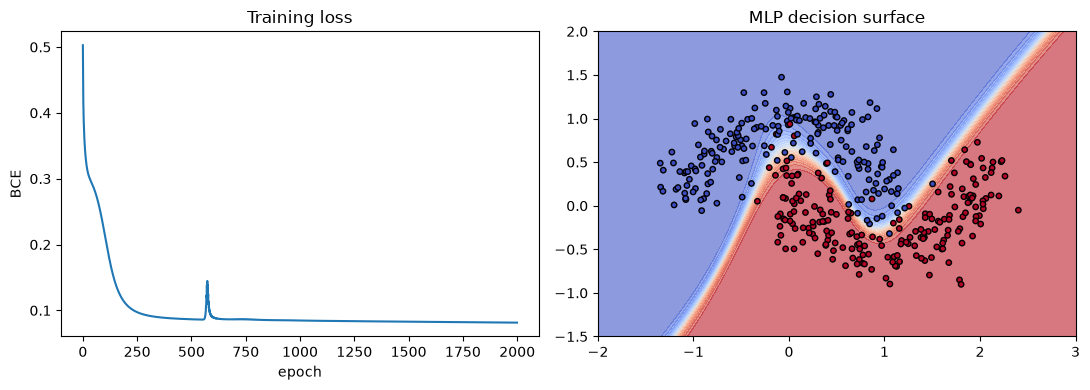

In [5]:
Xm, ym = make_moons(400, noise=0.2, random_state=0)
ym = ym[:, None].astype(float)
net = MLP([2, 16, 16, 1])
losses = []
for epoch in range(2000):
    net.forward(Xm); net.step(*net.backward(ym), lr=0.5)
    losses.append(net.loss(Xm, ym))
acc = ((net.forward(Xm) > 0.5) == ym).mean()
print("train accuracy:", acc)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(losses); axes[0].set(xlabel="epoch", ylabel="BCE", title="Training loss")
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
zz = net.forward(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.6)
axes[1].scatter(Xm[:, 0], Xm[:, 1], c=ym.ravel(), cmap="coolwarm", edgecolor="k", s=15)
axes[1].set_title("MLP decision surface"); plt.tight_layout(); plt.show()

## Takeaways
- Backprop costs about the same as a forward pass, no matter how many parameters there are.
- Hidden layers learn their **own features** — the XOR hidden layer above invented something like OR/NAND by itself.
- From here on, notebooks use PyTorch autograd, which automates exactly this backward pass (and runs on a GPU if you have one).